# 06 · Feature selection, interpretability and robustness

1. Apply the pre-registered family rule (notebook 05) to define the **candidate** set, then compact it with
   **training-only** LightGBM gain importance (no validation information).
2. Evaluate the compact set **F8** against the other families.
3. Interpret it: gain importance, validation permutation importance by family, TreeSHAP on a small sample.
4. Re-evaluate under the conservative origin conventions **B** (start of week) and **C** (case reporting delay).
5. Error analysis by city and in high-incidence periods; runtime and memory.

Locked 2025 test year: not loaded.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)
import numpy as np, pandas as pd
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
np.random.seed(2026)
import matplotlib.pyplot as plt
from cycler import cycler
import time, resource
from dengueshield.data import load_development_panel
from dengueshield.evaluation.folds import fold_data, dev_folds
from dengueshield.evaluation import ablation as ab
from dengueshield.evaluation.models import fit_predict, poisson_median
from dengueshield import metrics

OUT = ROOT / "reports/features"; FIG = OUT / "figures"; TAB = OUT / "tables"; SEL = OUT / "selection"
for d in (FIG, TAB, SEL): d.mkdir(parents=True, exist_ok=True)
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, GRID, SURF, MUTED = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb", "#b9b8b2"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF, "axes.edgecolor": INK2,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "lines.linewidth": 2, "font.size": 9.5, "axes.titlesize": 10.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "axes.prop_cycle": cycler(color=SERIES), "savefig.dpi": 130, "savefig.bbox": "tight"})
def save(fig, name):
    fig.savefig(FIG / f"{name}.png"); plt.show(); plt.close(fig)

panel = load_development_panel(); assert panel.date.dt.year.max() == 2024
man = fold_data(panel, "A_end_of_week", dev_folds()[0], 3).manifest
lib = ab.library(man); fam_of = man.set_index("feature").family.to_dict()
fwd = pd.read_csv(OUT / "forward_step_decision.csv")
S = {}
fwd.round(3)

,config,glm_gain,glm_folds_improved,lgbm_gain,lgbm_folds_improved,keep
0,F3plus_rain_lag,-0.037,0,-0.009,1,False
1,F3plus_rain_roll,-0.122,0,-0.020,1,False
2,F3plus_temp,-0.027,0,-0.016,1,False
3,F3plus_humidity,-0.026,1,0.005,3,False
4,F3plus_climate_int,-0.006,1,-0.005,2,False
5,F3plus_breeding,-0.004,1,0.004,2,False
6,F3plus_vuln,-0.001,1,0.000,2,False
7,F3plus_case,-0.042,0,0.001,2,False
8,F3plus_hist,-0.021,0,-0.023,1,False
9,F3plus_zero_infl,0.006,2,-0.004,0,False


## 1. Candidate set from the pre-registered rule

In [2]:
keep_fams = [c.replace("F3plus_", "") for c in fwd[fwd.keep].config]
base = lib["fam"]["calendar"] + lib["fam"]["static"] + lib["fam"]["rain_align"]
cand = base + [c for f in keep_fams for c in lib["fam"][f]]
S["families_kept_by_rule"] = keep_fams; S["candidate_n_features"] = len(cand)
print("families added to F3 by the rule:", keep_fams or "none", "| candidate features:", len(cand))

families added to F3 by the rule: none | candidate features: 38


## 2. Training-only compaction

Per (fold, horizon) a LightGBM is fitted on **training rows only** and gain shares are recorded. A feature is kept if its mean gain
share over the nine fits is at least 0.2%. Constant columns and the duplicate flags are dropped first. No validation score is used here.

In [3]:
from dengueshield.evaluation.models import LGBMModel
gain = []
for f in dev_folds():
    for h in (2, 3, 4):
        fd = fold_data(panel, "A_end_of_week", f, h)
        Xtr, ytr, *_ = fd.xy(cand)
        gain.append(LGBMModel().fit(Xtr, ytr).gain_importance().rename(f"{f.name}_h{h}"))
G = pd.concat(gain, axis=1); G["mean_gain_share"] = G.mean(axis=1)
G["family"] = G.index.map(fam_of); G = G.sort_values("mean_gain_share", ascending=False)
G.to_csv(TAB / "gain_importance_candidate_training_only.csv")
const = [c for c in cand if fold_data(panel, "A_end_of_week", dev_folds()[0], 3).X[c].nunique() <= 1]
f8 = [c for c in G.index if G.loc[c, "mean_gain_share"] >= 0.002 and c not in const]
f8 = [c for c in cand if c in set(f8)]   # keep library order
S["F8_n_features"] = len(f8); S["dropped_from_candidate"] = [c for c in cand if c not in f8]
print(len(cand), "->", len(f8), "features; dropped:", len(cand) - len(f8))
G.head(15)[["family", "mean_gain_share"]].round(4)

38 -> 24 features; dropped: 14


,family,mean_gain_share
cal_org_monsoon,calendar,0.3978
cal_org_cos1,calendar,0.1548
rain_win,rain_align,0.1347
rain_tl3,rain_align,0.0667
rain_tl4,rain_align,0.0314
regime_wet_now,rain_align,0.0260
waterlogging,static,0.0226
rain_clim_tl3,rain_align,0.0222
cal_tgt_sin2,calendar,0.0214
cal_tgt_cos3,calendar,0.0193


In [4]:
CFG = {"F3_aligned_rain": ab.configs(lib)["F3_aligned_rain"], "F8_candidate": cand, "F8_compact": f8,
       "F0_stage1_features": ab.STAGE1_COLS, "F2_rain_memory": ab.configs(lib)["F2_rain_memory"], "F7_combined": lib["all"]}
KEEP = ("F0_stage1_features", "F3_aligned_rain", "F8_compact", "F7_combined")
resA, predsA = ab.tournament(panel, CFG, conv="A_end_of_week", keep=KEEP, log=lambda *a: None)
lbA = ab.leaderboard(resA, "median")
lbA.sort_values(["model", "mae_avg"])[["config", "model", "mae_h2", "mae_h3", "mae_h4", "mae_avg", "fold_sd", "mae_val_2022", "mae_val_2023", "mae_val_2024", "rmse", "high_mae", "high_bias", "under_rate", "recall", "n_features"]].round(3)

horizon,config,model,mae_h2,mae_h3,mae_h4,mae_avg,fold_sd,mae_val_2022,mae_val_2023,mae_val_2024,rmse,high_mae,high_bias,under_rate,recall,n_features
4,F3_aligned_rain,glm,1.075,1.137,1.437,1.216,0.167,1.363,1.253,1.034,2.400,4.197,-3.004,0.227,0.607,38.0
8,F8_candidate,glm,1.075,1.137,1.437,1.216,0.167,1.363,1.253,1.034,2.400,4.197,-3.004,0.227,0.607,38.0
10,F8_compact,glm,1.069,1.148,1.453,1.223,0.162,1.367,1.254,1.048,2.422,4.240,-3.048,0.230,0.596,24.0
6,F7_combined,glm,1.082,1.201,1.543,1.275,0.184,1.449,1.293,1.083,2.523,4.624,-3.227,0.237,0.547,196.0
2,F2_rain_memory,glm,1.127,1.202,1.543,1.291,0.144,1.426,1.307,1.139,2.596,4.704,-3.306,0.246,0.555,59.0
0,F0_stage1_features,glm,1.103,1.229,1.546,1.293,0.157,1.435,1.320,1.124,2.581,4.679,-3.008,0.238,0.549,16.0
5,F3_aligned_rain,lgbm,1.102,1.167,1.476,1.248,0.209,1.475,1.207,1.063,2.512,4.274,-3.237,0.222,0.592,38.0
9,F8_candidate,lgbm,1.102,1.167,1.476,1.248,0.209,1.475,1.207,1.063,2.512,4.274,-3.237,0.222,0.592,38.0
11,F8_compact,lgbm,1.099,1.164,1.488,1.251,0.210,1.479,1.207,1.065,2.518,4.285,-3.173,0.221,0.591,24.0
1,F0_stage1_features,lgbm,1.147,1.195,1.459,1.267,0.236,1.487,1.296,1.018,2.549,4.341,-3.512,0.223,0.600,16.0


### Per-horizon configurations
A horizon-specific set is kept only if it beats the global F8 by at least 0.02 MAE **for both models** at that horizon.

In [5]:
tab = lbA.set_index(["config", "model"])
rows = []
for h in (2, 3, 4):
    for c in CFG:
        rows.append({"horizon": h, "config": c, **{m: tab.loc[(c, m), f"mae_h{h}"] for m in ("glm", "lgbm")}})
ph = pd.DataFrame(rows); ph["mean_two_models"] = ph[["glm", "lgbm"]].mean(axis=1)
ref = ph[ph.config == "F8_compact"].set_index("horizon")
ph["gain_vs_F8_glm"] = ph.apply(lambda r: ref.loc[r.horizon, "glm"] - r.glm, axis=1)
ph["gain_vs_F8_lgbm"] = ph.apply(lambda r: ref.loc[r.horizon, "lgbm"] - r.lgbm, axis=1)
ph["override"] = (ph.gain_vs_F8_glm >= 0.02) & (ph.gain_vs_F8_lgbm >= 0.02)
ph.round(3).to_csv(TAB / "per_horizon_config_comparison.csv", index=False)
S["per_horizon_overrides"] = ph[ph.override][["horizon", "config"]].to_dict("records")
print("overrides:", S["per_horizon_overrides"] or "none: one compact set is used for all horizons")
ph.pivot(index="config", columns="horizon", values="mean_two_models").round(3)

overrides: none: one compact set is used for all horizons


horizon,2,3,4
config,,,
F0_stage1_features,1.125,1.212,1.502
F2_rain_memory,1.133,1.199,1.533
F3_aligned_rain,1.089,1.152,1.457
F7_combined,1.085,1.194,1.540
F8_candidate,1.089,1.152,1.457
F8_compact,1.084,1.156,1.471


In [6]:
for h in (2, 3, 4):   # selection manifests; the prediction pipeline never reads these, Stage 3 does
    cols = f8
    (SEL / f"features_h{h}.json").write_text(json.dumps({"horizon": h, "convention": "A_end_of_week", "features": cols,
        "families": sorted({fam_of[c] for c in cols}), "n_features": len(cols), "rule": "pre-registered family rule + training-only gain >= 0.2%",
        "validation_folds_used_for_selection": ["val_2022", "val_2023", "val_2024"],
        "warning": "selected with chronological validation on only three seasons; 2025 untouched"}, indent=1))
pd.DataFrame({"feature": f8, "family": [fam_of[c] for c in f8], "mean_gain_share": [G.loc[c, "mean_gain_share"] for c in f8]}).to_csv(SEL / "F8_features.csv", index=False)
fam_count = pd.Series([fam_of[c] for c in f8]).value_counts(); fam_count

calendar      11
rain_align    10
static         3
Name: count, dtype: int64

## 3. Interpretability (descriptive; no causal claims)

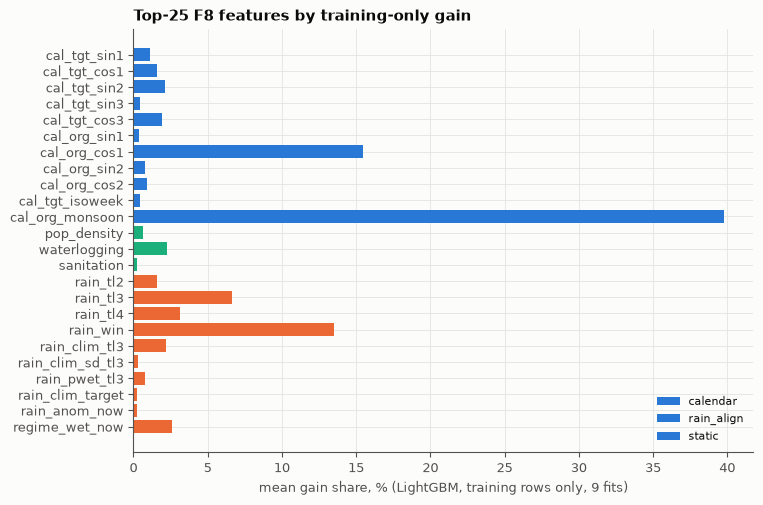

family
calendar      0.6491
rain_align    0.3116
static        0.0318
Name: mean_gain_share, dtype: float64

In [7]:
fig, ax = plt.subplots(figsize=(8, 5.5))
top = G.loc[f8].head(25).iloc[::-1]
colors = {f: SERIES[i % 8] for i, f in enumerate(sorted(set(top.family)))}
ax.barh(top.index, top.mean_gain_share * 100, color=[colors[f] for f in top.family])
for f, c in colors.items(): ax.barh([], [], color=c, label=f)
ax.set_xlabel("mean gain share, % (LightGBM, training rows only, 9 fits)"); ax.legend(fontsize=8, loc="lower right"); ax.set_title("Top-25 F8 features by training-only gain")
save(fig, "09_gain_importance_F8")
fam_gain = G.loc[f8].groupby("family").mean_gain_share.sum().sort_values(ascending=False); fam_gain.round(4)

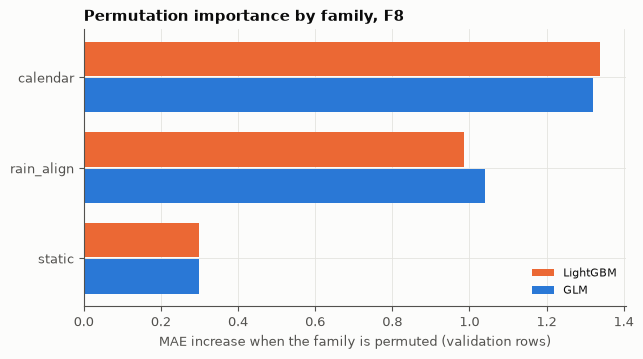

model,glm,lgbm
family,,
calendar,1.319,1.340
rain_align,1.041,0.986
static,0.298,0.298


In [8]:
# validation permutation importance by family: permute family columns jointly on the evaluation rows, 5 repeats
rng = np.random.default_rng(2026); rows = []
groups = {fa: [c for c in f8 if fam_of[c] == fa] for fa in sorted({fam_of[c] for c in f8})}
for model in ("lgbm", "glm"):
    for f in dev_folds():
        for h in (2, 3, 4):
            fd = fold_data(panel, "A_end_of_week", f, h); Xtr, ytr, Xev, yev, _ = fd.xy(f8)
            yrs = fd.meta.origin_date[fd.train.to_numpy()].dt.year.to_numpy()
            m, mu, _ = fit_predict(model, Xtr, ytr, Xev, years=yrs); base_mae = np.mean(np.abs(poisson_median(mu) - yev))
            for fa, cols in groups.items():
                inc = []
                for r in range(5):
                    Xp = Xev.copy(); perm = rng.permutation(len(Xp)); Xp[cols] = Xev[cols].to_numpy()[perm]
                    inc.append(np.mean(np.abs(poisson_median(m.predict(Xp)) - yev)) - base_mae)
                rows.append({"model": model, "fold": f.name, "horizon": h, "family": fa, "mae_increase": np.mean(inc)})
perm = pd.DataFrame(rows); perm.to_csv(TAB / "permutation_importance_by_family.csv", index=False)
pp = perm.groupby(["family", "model"]).mae_increase.mean().unstack("model").sort_values("lgbm", ascending=False)
S["permutation_importance_by_family"] = pp.round(4).to_dict("index")
fig, ax = plt.subplots(figsize=(7, 3.6)); y = np.arange(len(pp))
ax.barh(y - 0.2, pp.lgbm, 0.38, color=SERIES[1], label="LightGBM"); ax.barh(y + 0.2, pp.glm, 0.38, color=SERIES[0], label="GLM")
ax.set_yticks(y); ax.set_yticklabels(pp.index); ax.invert_yaxis(); ax.legend(fontsize=8); ax.set_xlabel("MAE increase when the family is permuted (validation rows)")
ax.set_title("Permutation importance by family, F8"); save(fig, "10_permutation_importance_family")
pp.round(3)

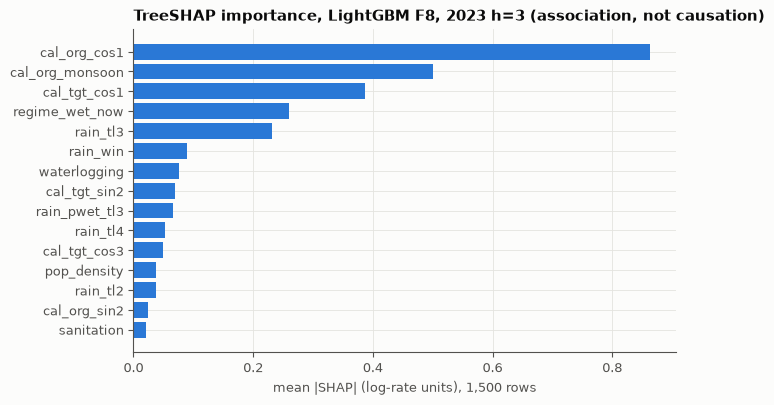

calendar      1.951
rain_align    0.787
static        0.136
dtype: float64

In [9]:
# TreeSHAP (LightGBM pred_contrib) on a fixed sample of 1,500 rows of val_2023, h=3
fd = fold_data(panel, "A_end_of_week", dev_folds()[1], 3); Xtr, ytr, Xev, yev, _ = fd.xy(f8)
m = LGBMModel().fit(Xtr, ytr); samp = Xev.sample(1500, random_state=2026)
sv = m.m.booster_.predict(samp, pred_contrib=True)[:, :-1]
shap_imp = pd.Series(np.abs(sv).mean(0), index=f8).sort_values(ascending=False); shap_imp.to_csv(TAB / "shap_mean_abs_F8_val2023_h3.csv")
fam_shap = shap_imp.groupby(shap_imp.index.map(fam_of)).sum().sort_values(ascending=False)
S["shap_top10"] = shap_imp.head(10).round(4).to_dict(); S["shap_by_family"] = fam_shap.round(4).to_dict()
fig, ax = plt.subplots(figsize=(7, 4.2)); top = shap_imp.head(15).iloc[::-1]
ax.barh(top.index, top.values, color=SERIES[0]); ax.set_xlabel("mean |SHAP| (log-rate units), 1,500 rows"); ax.set_title("TreeSHAP importance, LightGBM F8, 2023 h=3 (association, not causation)")
save(fig, "11_shap_F8"); fam_shap.round(3)

## 4. Convention robustness: B (start of week) and C (case reporting delay)

In [10]:
rows = []
for conv in ("A_end_of_week", "B_start_of_week", "C_case_delay"):
    r, _ = ab.tournament(panel, {k: CFG[k] for k in ("F0_stage1_features", "F2_rain_memory", "F3_aligned_rain", "F8_compact", "F7_combined")}, conv=conv, log=lambda *a: None)
    rows.append(ab.leaderboard(r, "median").assign(conv=conv))
conv = pd.concat(rows); conv.to_csv(OUT / "leaderboard_conventions.csv", index=False)
pv = conv.pivot_table(index=["config", "model"], columns="conv", values="mae_avg").round(3)
pv["B_minus_A"] = pv.B_start_of_week - pv.A_end_of_week; pv["C_minus_A"] = pv.C_case_delay - pv.A_end_of_week
pv.to_csv(TAB / "convention_sensitivity_avg_mae.csv"); pv

conv                      A_end_of_week  B_start_of_week  C_case_delay  B_minus_A  C_minus_A
config             model                                                                    
F0_stage1_features glm            1.293            1.438         1.280      0.145     -0.013
                   lgbm           1.267            1.375         1.268      0.108      0.001
F2_rain_memory     glm            1.291            1.425         1.291      0.134      0.000
                   lgbm           1.286            1.424         1.288      0.138      0.002
F3_aligned_rain    glm            1.216            1.341         1.216      0.125      0.000
                   lgbm           1.248            1.403         1.256      0.155      0.008
F7_combined        glm            1.275            1.437         1.278      0.162      0.003
                   lgbm           1.271            1.404         1.266      0.133     -0.005
F8_compact         glm            1.223            1.332         1.223      0.109      0.000
                   lgbm           1.251            1.401         1.251      0.150      0.000

In [11]:
conv[conv.config.isin(["F0_stage1_features", "F8_compact"])].pivot_table(index=["config", "model", "conv"], values=["mae_h2", "mae_h3", "mae_h4", "mae_avg"]).round(3)

horizon                                   mae_avg  mae_h2  mae_h3  mae_h4
config             model conv                                            
F0_stage1_features glm   A_end_of_week      1.293   1.103   1.229   1.546
                         B_start_of_week    1.438   1.205   1.515   1.595
                         C_case_delay       1.280   1.096   1.218   1.526
                   lgbm  A_end_of_week      1.267   1.147   1.195   1.459
                         B_start_of_week    1.375   1.165   1.426   1.532
                         C_case_delay       1.268   1.151   1.195   1.459
F8_compact         glm   A_end_of_week      1.223   1.069   1.148   1.453
                         B_start_of_week    1.332   1.106   1.385   1.505
                         C_case_delay       1.223   1.068   1.148   1.453
                   lgbm  A_end_of_week      1.251   1.099   1.164   1.488
                         B_start_of_week    1.401   1.154   1.448   1.603
                         C_case_delay       1.251   1.100   1.165   1.487

## 5. Error analysis: Stage 1 features vs F3 vs F8 (convention A, Poisson median)

In [12]:
P = predsA[(predsA.kind == "median") & predsA.config.isin(["F0_stage1_features", "F3_aligned_rain", "F8_compact"])].copy()
P["abs_err"] = (P.y_pred - P.y_true).abs(); P["err"] = P.y_pred - P.y_true
thr = {f.name: metrics.thresholds(fold_data(panel, "A_end_of_week", f, 3).xy(["pop_density"])[1])["outbreak"] for f in dev_folds()}
P["high"] = P.y_true >= P.fold.map(thr)
P["peak_months"] = P.target_date.dt.month.isin([7, 8, 9])
city = P.groupby(["config", "model", "city"]).abs_err.mean().unstack("city").round(3); city.to_csv(TAB / "error_by_city.csv")
hi = P.groupby(["config", "model", "high"]).agg(mae=("abs_err", "mean"), bias=("err", "mean"), under=("err", lambda e: (e < 0).mean()), n=("err", "size")).round(3)
hi.to_csv(TAB / "error_high_incidence.csv")
pk = P.groupby(["config", "model", "peak_months"]).agg(mae=("abs_err", "mean"), bias=("err", "mean")).round(3); pk.to_csv(TAB / "error_peak_months.csv")
S["error_high_incidence_F8"] = hi.loc["F8_compact"].reset_index().to_dict("records")
display(city); hi.loc[["F0_stage1_features", "F8_compact"]]

city                      Chattogram  Dhaka North  Dhaka South  Gazipur  Narayanganj
config             model                                                            
F0_stage1_features glm         1.258        1.282        1.274    1.472        1.255
                   lgbm        1.232        1.250        1.240    1.482        1.253
F3_aligned_rain    glm         1.164        1.196        1.211    1.392        1.205
                   lgbm        1.217        1.239        1.217    1.432        1.247
F8_compact         glm         1.183        1.195        1.219    1.398        1.213
                   lgbm        1.215        1.244        1.219    1.433        1.245

mae   bias  under      n
config             model high                             
F0_stage1_features glm   False  0.760  0.196  0.156  23091
                         True   4.728 -3.272  0.769   3549
                   lgbm  False  0.764  0.299  0.136  23091
                         True   4.510 -3.760  0.787   3549
F8_compact         glm   False  0.741  0.242  0.147  23091
                         True   4.335 -3.245  0.773   3549
                   lgbm  False  0.763  0.302  0.137  23091
                         True   4.394 -3.425  0.764   3549

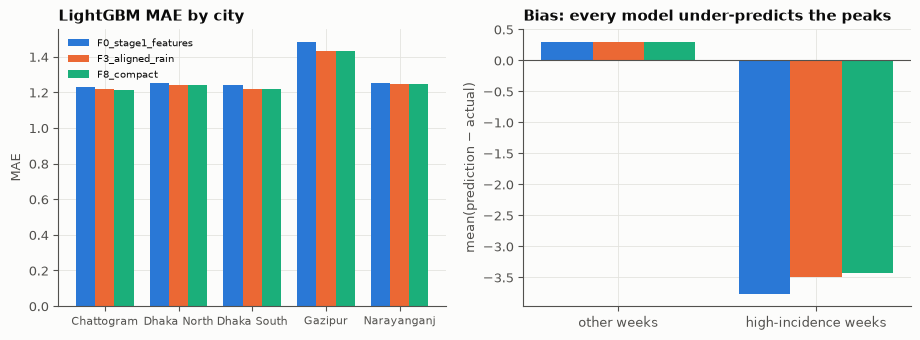

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
cc = city.xs("lgbm", level="model"); x = np.arange(cc.shape[1])
for i, (cfgname, row) in enumerate(cc.iterrows()): ax[0].bar(x + (i - 1) * 0.26, row.values, 0.26, color=SERIES[i], label=cfgname)
ax[0].set_xticks(x); ax[0].set_xticklabels(cc.columns, fontsize=8); ax[0].set_ylabel("MAE"); ax[0].set_title("LightGBM MAE by city"); ax[0].legend(fontsize=7.5)
hh = hi.xs("lgbm", level="model").reset_index(); hh["slice"] = hh.high.map({True: "high-incidence weeks", False: "other weeks"})
for i, (cfgname, d) in enumerate(hh.groupby("config")): ax[1].bar(np.arange(2) + (i - 1) * 0.26, d.sort_values("high").bias.values, 0.26, color=SERIES[i], label=cfgname)
ax[1].set_xticks(range(2)); ax[1].set_xticklabels(["other weeks", "high-incidence weeks"]); ax[1].axhline(0, color=INK2, lw=0.8)
ax[1].set_ylabel("mean(prediction − actual)"); ax[1].set_title("Bias: every model under-predicts the peaks")
save(fig, "12_error_city_and_high_incidence")

## 6. Runtime and memory

In [14]:
rt = resA[(resA.kind == "median")].groupby(["config", "model"]).agg(fit_s_per_fit=("fit_s", "mean"), predict_s=("predict_s", "mean"),
        n_eval=("n_eval", "mean"), features=("n_features", "first"), build_s=("build_s", "mean")).reset_index()
rt["predict_ms_per_1000_rows"] = rt.predict_s / rt.n_eval * 1e6
rt["total_inference_ms_one_origin_60_wards"] = (rt.build_s + rt.predict_s * 60 / rt.n_eval) * 1e3
rt["peak_rss_MB_process"] = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e6
rt.round(3).to_csv(OUT / "runtime_by_config.csv", index=False); S["peak_rss_MB"] = round(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e6)
rt.round(3)

,config,model,fit_s_per_fit,predict_s,n_eval,features,build_s,predict_ms_per_1000_rows,total_inference_ms_one_origin_60_wards,peak_rss_MB_process
0,F0_stage1_features,glm,0.103,0.000,2960.0,16,0.133,0.124,133.498,766.64
1,F0_stage1_features,lgbm,0.407,0.005,2960.0,16,0.133,1.608,133.587,766.64
2,F2_rain_memory,glm,0.852,0.001,2960.0,59,0.137,0.206,136.778,766.64
3,F2_rain_memory,lgbm,0.494,0.005,2960.0,59,0.137,1.674,136.866,766.64
4,F3_aligned_rain,glm,0.382,0.000,2960.0,38,0.133,0.135,133.498,766.64
5,F3_aligned_rain,lgbm,0.461,0.006,2960.0,38,0.133,1.938,133.606,766.64
6,F7_combined,glm,3.605,0.002,2960.0,196,0.133,0.613,133.527,766.64
7,F7_combined,lgbm,0.902,0.006,2960.0,196,0.133,1.953,133.607,766.64
8,F8_candidate,glm,0.354,0.000,2960.0,38,0.133,0.153,133.499,766.64
9,F8_candidate,lgbm,0.435,0.005,2960.0,38,0.133,1.629,133.588,766.64


## 7. Final tables: per-horizon metrics, Stage 1 comparison and verification of the importance computations

In [15]:
r = resA[resA.kind == "median"]
ph_m = r.groupby(["config", "model", "horizon"]).agg(mae=("all_mae", "mean"), rmse=("all_rmse", "mean"), poisson_dev=("all_poisson_dev", "mean"),
        high_mae=("high_mae", "mean"), high_bias=("high_bias", "mean"), bias=("all_bias", "mean"), under_rate=("all_under_rate", "mean"),
        recall=("outbreak_recall", "mean"), precision=("outbreak_precision", "mean"), tier_acc=("tier_accuracy", "mean")).reset_index()
ph_m.round(4).to_csv(TAB / "final_per_horizon_metrics.csv", index=False)
yr = r.pivot_table(index=["config", "model", "horizon"], columns="fold", values="all_mae").round(3); yr.to_csv(TAB / "final_mae_by_year_and_horizon.csv")
display(ph_m[ph_m.config.isin(["F3_aligned_rain", "F8_compact", "F7_combined", "F0_stage1_features"])].round(3))

,config,model,horizon,mae,rmse,poisson_dev,high_mae,high_bias,bias,under_rate,recall,precision,tier_acc
0,F0_stage1_features,glm,2,1.103,2.215,1.285,4.147,-2.989,-0.319,0.242,0.568,0.803,0.782
1,F0_stage1_features,glm,3,1.229,2.445,1.413,4.450,-2.521,-0.261,0.238,0.564,0.751,0.759
2,F0_stage1_features,glm,4,1.546,3.082,1.885,5.441,-3.513,-0.225,0.234,0.516,0.620,0.709
3,F0_stage1_features,lgbm,2,1.147,2.329,1.289,3.976,-3.381,-0.239,0.221,0.617,0.728,0.783
4,F0_stage1_features,lgbm,3,1.195,2.399,1.340,4.078,-3.281,-0.274,0.227,0.612,0.748,0.765
5,F0_stage1_features,lgbm,4,1.459,2.919,1.768,4.970,-3.875,-0.222,0.223,0.572,0.623,0.729
12,F3_aligned_rain,glm,2,1.075,2.146,1.247,3.907,-2.688,-0.214,0.228,0.620,0.799,0.787
13,F3_aligned_rain,glm,3,1.137,2.225,1.352,3.847,-2.622,-0.192,0.226,0.632,0.761,0.772
14,F3_aligned_rain,glm,4,1.437,2.828,1.717,4.836,-3.703,-0.217,0.228,0.569,0.641,0.728
15,F3_aligned_rain,lgbm,2,1.102,2.251,1.270,3.972,-3.152,-0.276,0.227,0.587,0.771,0.788


In [16]:
s1 = pd.read_csv(ROOT / "reports/baselines/metrics_summary.csv").set_index(["model", "horizon"])
bench = {2: 1.094, 3: 1.213, 4: 1.517}
rows = []
for cfg, mdl in [("F3_aligned_rain", "glm"), ("F8_compact", "glm"), ("F3_aligned_rain", "lgbm"), ("F8_compact", "lgbm"), ("F7_combined", "glm")]:
    for h in (2, 3, 4):
        x = ph_m[(ph_m.config == cfg) & (ph_m.model == mdl) & (ph_m.horizon == h)].iloc[0]
        rows.append({"stage2_config": cfg, "model": mdl, "horizon": h, "stage1_mae": bench[h], "stage2_mae": x.mae, "mae_reduction_pct": 100 * (bench[h] - x.mae) / bench[h],
                     "stage1_rmse_median_glm": s1.loc[("poisson_glm_poisson_median", h), "all_rmse"], "stage2_rmse": x.rmse,
                     "stage1_high_mae": s1.loc[("poisson_glm_poisson_median", h), "high_mae"], "stage2_high_mae": x.high_mae,
                     "stage1_recall": s1.loc[("poisson_glm_poisson_median", h), "outbreak_recall"], "stage2_recall": x.recall})
cmp1 = pd.DataFrame(rows); cmp1.round(4).to_csv(TAB / "stage1_vs_stage2.csv", index=False)
avg = cmp1.groupby(["stage2_config", "model"]).agg(stage1_avg=("stage1_mae", "mean"), stage2_avg=("stage2_mae", "mean")); avg["reduction_pct"] = 100 * (avg.stage1_avg - avg.stage2_avg) / avg.stage1_avg
S["stage1_vs_stage2_avg"] = avg.round(4).reset_index().to_dict("records")
display(cmp1.round(3)); avg.round(3)

,stage2_config,model,horizon,stage1_mae,stage2_mae,mae_reduction_pct,stage1_rmse_median_glm,stage2_rmse,stage1_high_mae,stage2_high_mae,stage1_recall,stage2_recall
0,F3_aligned_rain,glm,2,1.094,1.075,1.737,2.189,2.146,4.088,3.907,0.568,0.620
1,F3_aligned_rain,glm,3,1.213,1.137,6.259,2.398,2.225,4.356,3.847,0.563,0.632
2,F3_aligned_rain,glm,4,1.517,1.437,5.280,3.059,2.828,5.400,4.836,0.523,0.569
3,F8_compact,glm,2,1.094,1.069,2.323,2.189,2.124,4.088,3.812,0.568,0.628
4,F8_compact,glm,3,1.213,1.148,5.358,2.398,2.271,4.356,3.946,0.563,0.623
5,F8_compact,glm,4,1.517,1.453,4.222,3.059,2.870,5.400,4.962,0.523,0.538
6,F3_aligned_rain,lgbm,2,1.094,1.102,-0.743,2.189,2.251,4.088,3.972,0.568,0.587
7,F3_aligned_rain,lgbm,3,1.213,1.167,3.792,2.398,2.347,4.356,4.088,0.563,0.598
8,F3_aligned_rain,lgbm,4,1.517,1.476,2.688,3.059,2.939,5.400,4.763,0.523,0.590
9,F8_compact,lgbm,2,1.094,1.099,-0.497,2.189,2.252,4.088,3.994,0.568,0.582


stage1_avg  stage2_avg  reduction_pct
stage2_config   model                                       
F3_aligned_rain glm         1.275       1.216          4.577
                lgbm        1.275       1.248          2.057
F7_combined     glm         1.275       1.275         -0.060
F8_compact      glm         1.275       1.223          4.039
                lgbm        1.275       1.251          1.896

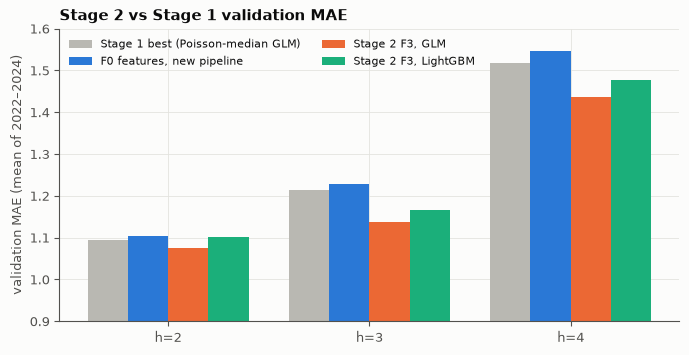

In [17]:
fig, ax = plt.subplots(figsize=(8, 3.8)); x = np.arange(3); w = 0.2
ax.bar(x - 1.5 * w, [bench[h] for h in (2, 3, 4)], w, color=MUTED, label="Stage 1 best (Poisson-median GLM)")
for i, (cfg, mdl, lab) in enumerate([("F0_stage1_features", "glm", "F0 features, new pipeline"), ("F3_aligned_rain", "glm", "Stage 2 F3, GLM"), ("F3_aligned_rain", "lgbm", "Stage 2 F3, LightGBM")]):
    v = [ph_m[(ph_m.config == cfg) & (ph_m.model == mdl) & (ph_m.horizon == h)].mae.iloc[0] for h in (2, 3, 4)]
    ax.bar(x + (i - 0.5) * w, v, w, color=SERIES[i], label=lab)
ax.set_xticks(x); ax.set_xticklabels(["h=2", "h=3", "h=4"]); ax.set_ylim(0.9, 1.6); ax.set_ylabel("validation MAE (mean of 2022–2024)")
ax.legend(fontsize=8, ncol=2); ax.set_title("Stage 2 vs Stage 1 validation MAE"); save(fig, "13_stage1_vs_stage2")

### Top-20 features with importance evidence (F8, training-only gain; SHAP and permutation are validation-based)

In [18]:
gcv = G.drop(columns=["family", "mean_gain_share"]).std(axis=1) / G.mean_gain_share
top20 = pd.DataFrame({"family": G.loc[f8].family, "gain_share_mean": G.loc[f8].mean_gain_share, "gain_cv_across_9_fits": gcv.loc[f8],
                      "mean_abs_shap_val2023_h3": shap_imp.reindex(f8)}).sort_values("gain_share_mean", ascending=False).head(20)
top20.round(4).to_csv(TAB / "top20_features.csv"); top20.round(3)

,family,gain_share_mean,gain_cv_across_9_fits,mean_abs_shap_val2023_h3
cal_org_monsoon,calendar,0.398,0.122,0.500
cal_org_cos1,calendar,0.155,0.787,0.863
rain_win,rain_align,0.135,1.358,0.089
rain_tl3,rain_align,0.067,0.886,0.232
rain_tl4,rain_align,0.031,0.748,0.052
regime_wet_now,rain_align,0.026,0.992,0.261
waterlogging,static,0.023,0.014,0.076
rain_clim_tl3,rain_align,0.022,0.932,0.018
cal_tgt_sin2,calendar,0.021,0.572,0.070
cal_tgt_cos3,calendar,0.019,0.568,0.048


### Verification that SHAP and permutation importance were computed correctly
* **TreeSHAP additivity:** per-row contributions plus the bias term must equal LightGBM's raw (log-rate) prediction.
* **Permutation sanity:** permuting *no* column leaves MAE unchanged; permuting *every* column must hurt substantially; the union of
  family permutations must be consistent with that (each family increase is non-negative on average).
* **Reproduction:** one result is recomputed from scratch (bypassing the cache) and compared with the saved leaderboard.

In [19]:
full = m.m.booster_.predict(samp, pred_contrib=True); raw = m.m.booster_.predict(samp, raw_score=True)
add_err = float(np.abs(full.sum(1) - raw).max())
fd = fold_data(panel, "A_end_of_week", dev_folds()[1], 3); Xtr, ytr, Xev, yev, _ = fd.xy(f8)
mm_, mu, _ = fit_predict("lgbm", Xtr, ytr, Xev); b0 = np.mean(np.abs(poisson_median(mu) - yev))
rng2 = np.random.default_rng(7); Xp = Xev.copy(); Xp[:] = Xev.to_numpy()[rng2.permutation(len(Xev))]
b_all = np.mean(np.abs(poisson_median(mm_.predict(Xp)) - yev)); b_none = np.mean(np.abs(poisson_median(mm_.predict(Xev.copy())) - yev))
fam_nonneg = bool((perm.groupby(["family", "model"]).mae_increase.mean() >= -1e-9).all())
# from-scratch reproduction of a saved leaderboard value (no cache)
cols = CFG["F3_aligned_rain"]; fdr = fold_data(panel, "A_end_of_week", dev_folds()[1], 3); Xt, yt, Xe, ye, _ = fdr.xy(cols)
yrs = fdr.meta.origin_date[fdr.train.to_numpy()].dt.year.to_numpy(); _, mu2, _ = fit_predict("glm", Xt, yt, Xe, years=yrs)
fresh = float(np.mean(np.abs(poisson_median(mu2) - ye)))
saved = float(resA[(resA.config == "F3_aligned_rain") & (resA.model == "glm") & (resA.kind == "median") & (resA.fold == "val_2023") & (resA.horizon == 3)].all_mae.iloc[0])
S["verification"] = {"shap_additivity_max_abs_error": add_err, "permute_none_delta_mae": float(b_none - b0), "permute_all_delta_mae": float(b_all - b0),
                     "family_permutation_nonnegative": fam_nonneg, "reproduced_mae": fresh, "saved_mae": saved, "reproduction_abs_diff": abs(fresh - saved)}
assert add_err < 1e-6 and abs(b_none - b0) < 1e-12 and b_all - b0 > 0.5 and abs(fresh - saved) < 1e-9, S["verification"]
S["verification"]

{'shap_additivity_max_abs_error': 5.773159728050814e-15,
 'permute_none_delta_mae': 0.0,
 'permute_all_delta_mae': 3.852380952380953,
 'family_permutation_nonnegative': True,
 'reproduced_mae': 1.1438775510204082,
 'saved_mae': 1.1438775510204082,
 'reproduction_abs_diff': 0.0}

In [20]:
(OUT / "selection_summary.json").write_text(json.dumps(S, indent=2, default=float))
print(json.dumps({k: S[k] for k in ["families_kept_by_rule", "candidate_n_features", "F8_n_features", "per_horizon_overrides"]}, indent=1))

{
 "families_kept_by_rule": [],
 "candidate_n_features": 38,
 "F8_n_features": 24,
 "per_horizon_overrides": []
}
